# proSIM - SIM misuse detection: model training

Trains and evaluates two models on the synthetic CDR data (one row per SIM per day):

| Model | Type | Role |
|---|---|---|
| **Isolation Forest** | Unsupervised | Flags SIM-days with unusual usage, without using labels |
| **Random Forest** | Supervised (multiclass) | Classifies each SIM-day: `normal`, `unauthorized_sharing`, `data_reselling`, `ghost_usage`, `inactive_billing` |

Each section matches an issue in the **ML Training** milestone. Kernel: **proSIM (ml-service venv)**.

## 1. Setup and load data  (issue #1)

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

SEED = 42
np.random.seed(SEED)

# Locate the ml-training folder whether the kernel starts in notebooks/ or elsewhere.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and p.name == "ml-training")
DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports"
MODELS_DIR = ROOT.parent / "ml-service" / "models"
REPORTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Data:", DATA_DIR)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4
Data: C:\Users\user\Downloads\proSIM\ml-training\data


In [2]:
agg = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_agg.csv")
labels = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_labels.csv")

df = agg.merge(labels, on=["sim_id", "date"], how="left", validate="one_to_one")
assert df["label"].notna().all(), "every SIM-day must have a label"
df = df.sort_values(["sim_id", "date"]).reset_index(drop=True)

print(f"{len(df):,} SIM-days | {df.sim_id.nunique():,} SIMs | {df.date.min()} to {df.date.max()}")
df.head()

90,000 SIM-days | 1,000 SIMs | 2025-01-01 to 2025-03-31


,sim_id,date,total_download_mb,total_upload_mb,session_count,total_duration_s,hotspot_flag_count,geo_flag_count,roaming_sessions,unique_towers,...,offpeak_mb,max_session_mb,total_mb,billed_mb,tier,voice_minutes_used,sms_count,voice_minutes_remaining,sms_remaining,label
0,0,2025-01-01,365.86490,149.2379,10,1643,0,0,0,3,...,0.000000,170.04741,515.10280,515.103,professional,4.967,1,195.03,134,normal
1,0,2025-01-02,315.47680,148.7202,8,2627,0,0,0,3,...,0.000000,234.70801,464.19702,464.197,professional,4.033,1,191.00,133,normal
2,0,2025-01-03,338.00360,128.7998,11,3950,0,0,0,3,...,0.000000,127.63780,466.80340,466.803,professional,7.000,3,184.00,130,normal
3,0,2025-01-04,212.05319,61.7085,12,2060,0,0,0,2,...,11.541901,110.95750,273.76170,273.762,professional,1.783,4,182.22,126,normal
4,0,2025-01-05,134.54870,130.8992,9,2009,0,0,0,2,...,0.000000,142.36870,265.44790,265.448,professional,1.667,2,180.55,124,normal


In [3]:
# Columns and types, to plan feature engineering
df.dtypes.to_frame("dtype").T

,sim_id,date,total_download_mb,total_upload_mb,session_count,total_duration_s,hotspot_flag_count,geo_flag_count,roaming_sessions,unique_towers,...,offpeak_mb,max_session_mb,total_mb,billed_mb,tier,voice_minutes_used,sms_count,voice_minutes_remaining,sms_remaining,label
dtype,int64,str,float64,float64,int64,int64,int64,int64,int64,int64,...,float64,float64,float64,float64,str,float64,int64,float64,int64,str


## 2. Exploratory data analysis  (issue #2)

- [x] Label distribution table and chart (about 5% misuse)
- [x] Compare usage patterns of each misuse type against normal
- [x] Check and document that `billed_mb > total_mb` exactly separates inactive billing

Figures are saved to `reports/` for the write-up.

### 2.1 Data quality

In [4]:
# Class order and colours, reused by every chart in this notebook
CLASS_ORDER = ["normal", "unauthorized_sharing", "data_reselling", "ghost_usage", "inactive_billing"]
MISUSE = CLASS_ORDER[1:]
SHORT = {"normal": "normal", "unauthorized_sharing": "sharing", "data_reselling": "reselling",
         "ghost_usage": "ghost", "inactive_billing": "inactive\nbilling"}
CLASS_COLORS = {"normal": "#9a9893", "unauthorized_sharing": "#2a78d6", "data_reselling": "#eb6834",
                "ghost_usage": "#1baf7a", "inactive_billing": "#eda100"}

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#b8b6b0", "axes.labelcolor": "#52514e", "axes.titlesize": 11,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})

def savefig(fig, name):
    fig.savefig(REPORTS_DIR / name, dpi=150, bbox_inches="tight")

numeric = df.select_dtypes("number")
days_per_sim = df.groupby("sim_id").size()
negatives = (numeric < 0).sum()
print("Missing values:              ", int(df.isna().sum().sum()))
print("Duplicate (sim_id, date) rows:", int(df.duplicated(["sim_id", "date"]).sum()))
print("Days per SIM:                 ", days_per_sim.min(), "to", days_per_sim.max())
print("Columns with negative values: ", negatives[negatives > 0].to_dict() or "none")

Missing values:               0
Duplicate (sim_id, date) rows: 0
Days per SIM:                  90 to 90
Columns with negative values:  {'voice_minutes_remaining': 32}


### 2.2 Label distribution

In [5]:
counts = df["label"].value_counts().reindex(CLASS_ORDER)
sims_affected = df.groupby("label")["sim_id"].nunique().reindex(CLASS_ORDER)
dist = pd.DataFrame({
    "SIM-days": counts,
    "share of days (%)": (100 * counts / len(df)).round(2),
    "SIMs affected": sims_affected,
})
dist.loc["normal", "SIMs affected"] = np.nan  # every SIM has normal days

misuse_sims = df.loc[df.label != "normal", "sim_id"].nunique()
print(f"Misuse days: {(df.label != 'normal').mean():.2%} of all SIM-days")
print(f"SIMs with at least one misuse day: {misuse_sims} of {df.sim_id.nunique()}")
dist

Misuse days: 5.44% of all SIM-days
SIMs with at least one misuse day: 318 of 1000


,SIM-days,share of days (%),SIMs affected
label,,,
normal,85101,94.56,NaN
unauthorized_sharing,1958,2.18,120.0
data_reselling,752,0.84,85.0
ghost_usage,1397,1.55,85.0
inactive_billing,792,0.88,58.0


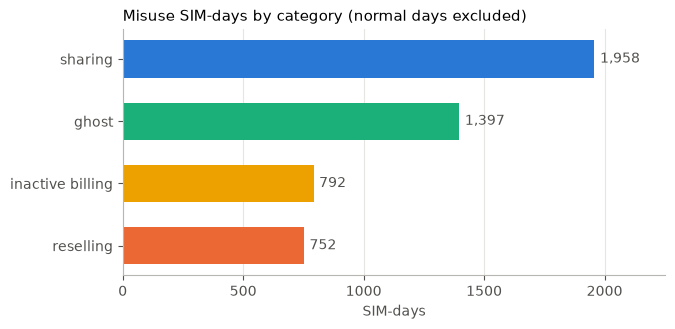

In [6]:
m = dist.loc[MISUSE, "SIM-days"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh([SHORT[c].replace("\n", " ") for c in m.index], m.values, height=0.6,
               color=[CLASS_COLORS[c] for c in m.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in m.values], padding=4, color="#52514e")
ax.set_xlabel("SIM-days")
ax.set_title("Misuse SIM-days by category (normal days excluded)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, m.max() * 1.15)
savefig(fig, "eda_label_distribution.png")
plt.show()

### 2.3 Misuse episodes
Each misuse is an *episode*: a run of consecutive days on one SIM.

In [7]:
episodes = pd.read_csv(DATA_DIR / "synthetic_cdr_labels.csv")
ep = episodes.groupby("category")["duration_days"].agg(
    episodes="count", median_days="median", min_days="min", max_days="max").reindex(MISUSE)
multi = episodes.groupby("sim_id").size()
print(f"{len(episodes)} episodes on {episodes.sim_id.nunique()} SIMs; "
      f"{(multi > 1).sum()} SIMs have more than one episode")
ep

355 episodes on 318 SIMs; 35 SIMs have more than one episode


,episodes,median_days,min_days,max_days
category,,,,
unauthorized_sharing,123,11.0,1,71
data_reselling,87,5.0,1,38
ghost_usage,86,10.5,1,72
inactive_billing,59,9.0,1,65


### 2.4 How each misuse type differs from normal usage
Medians per class. Shares are computed here only for exploration; they are built properly in section 3.

In [8]:
eda = df.copy()
eps = 1e-6
eda["upload_share"] = eda["total_upload_mb"] / (eda["total_mb"] + eps)
eda["offpeak_share"] = eda["offpeak_mb"] / (eda["total_mb"] + eps)
eda["mb_per_session"] = eda["total_mb"] / (eda["session_count"] + eps)
eda["billed_minus_used_mb"] = eda["billed_mb"] - eda["total_mb"]

COMPARE = ["total_mb", "total_upload_mb", "upload_share", "session_count", "mb_per_session",
           "max_session_mb", "hotspot_flag_count", "unique_towers", "geo_flag_count",
           "roaming_sessions", "apn_public_count", "offpeak_share", "voice_minutes_used",
           "sms_count", "billed_minus_used_mb"]
medians = eda.groupby("label")[COMPARE].median().reindex(CLASS_ORDER).T
medians.columns = [SHORT[c].replace("\n", " ") for c in medians.columns]
medians.round(2)

,normal,sharing,reselling,ghost,inactive billing
total_mb,393.32,1016.78,602.88,13.05,0.0
total_upload_mb,112.88,285.50,168.96,3.78,0.0
upload_share,0.29,0.30,0.30,0.29,0.0
session_count,10.00,10.00,10.00,6.00,5.0
mb_per_session,40.91,104.97,60.49,2.23,0.0
max_session_mb,180.96,453.24,284.27,6.22,0.0
hotspot_flag_count,0.00,2.00,0.00,0.00,0.0
unique_towers,3.00,3.00,3.00,2.00,2.0
geo_flag_count,0.00,0.00,0.00,0.00,0.0
roaming_sessions,0.00,0.00,0.00,0.00,0.0


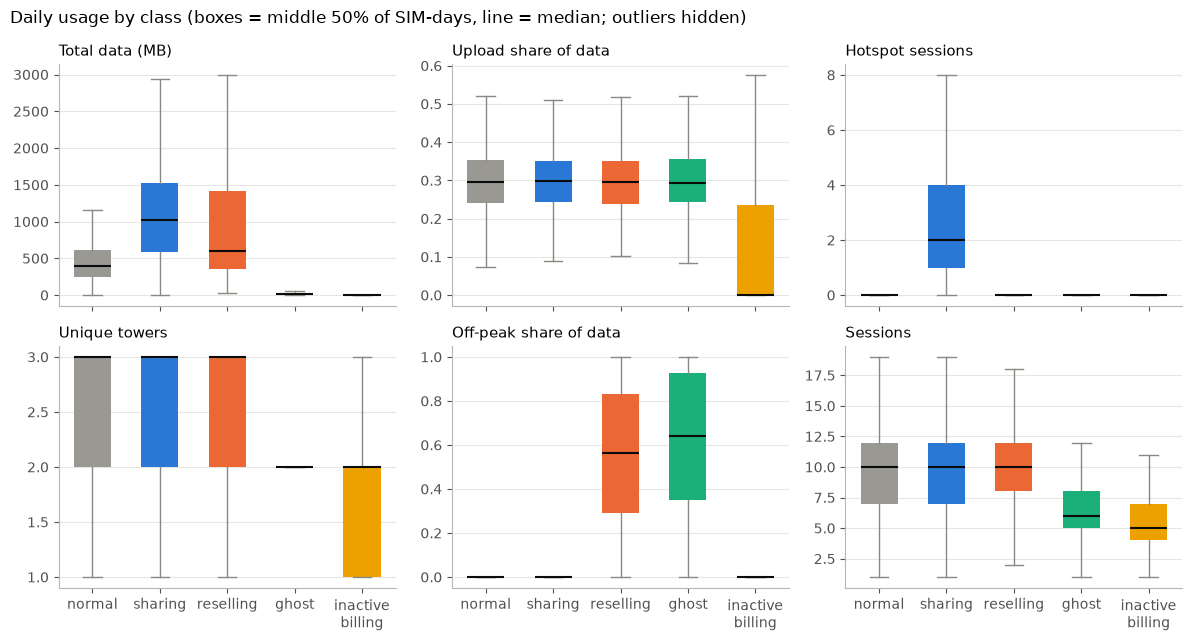

In [9]:
PANELS = [("total_mb", "Total data (MB)"), ("upload_share", "Upload share of data"),
          ("hotspot_flag_count", "Hotspot sessions"), ("unique_towers", "Unique towers"),
          ("offpeak_share", "Off-peak share of data"), ("session_count", "Sessions")]

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True)
for ax, (col, title) in zip(axes.flat, PANELS):
    data = [eda.loc[eda.label == c, col].values for c in CLASS_ORDER]
    bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                    medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                    whiskerprops={"color": "#8a8883"}, capprops={"color": "#8a8883"},
                    boxprops={"linewidth": 0})
    for patch, c in zip(bp["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[c])
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
for ax in axes[-1]:
    ax.set_xticks(range(1, len(CLASS_ORDER) + 1), [SHORT[c] for c in CLASS_ORDER])
fig.suptitle("Daily usage by class (boxes = middle 50% of SIM-days, line = median; outliers hidden)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
savefig(fig, "eda_usage_by_class.png")
plt.show()

### 2.5 Misuse as a change in a SIM's own behaviour
One example SIM per misuse type: daily data use, with the misuse episode shaded. Comparing a day with the same SIM's recent past is the idea behind the baseline features in section 3.

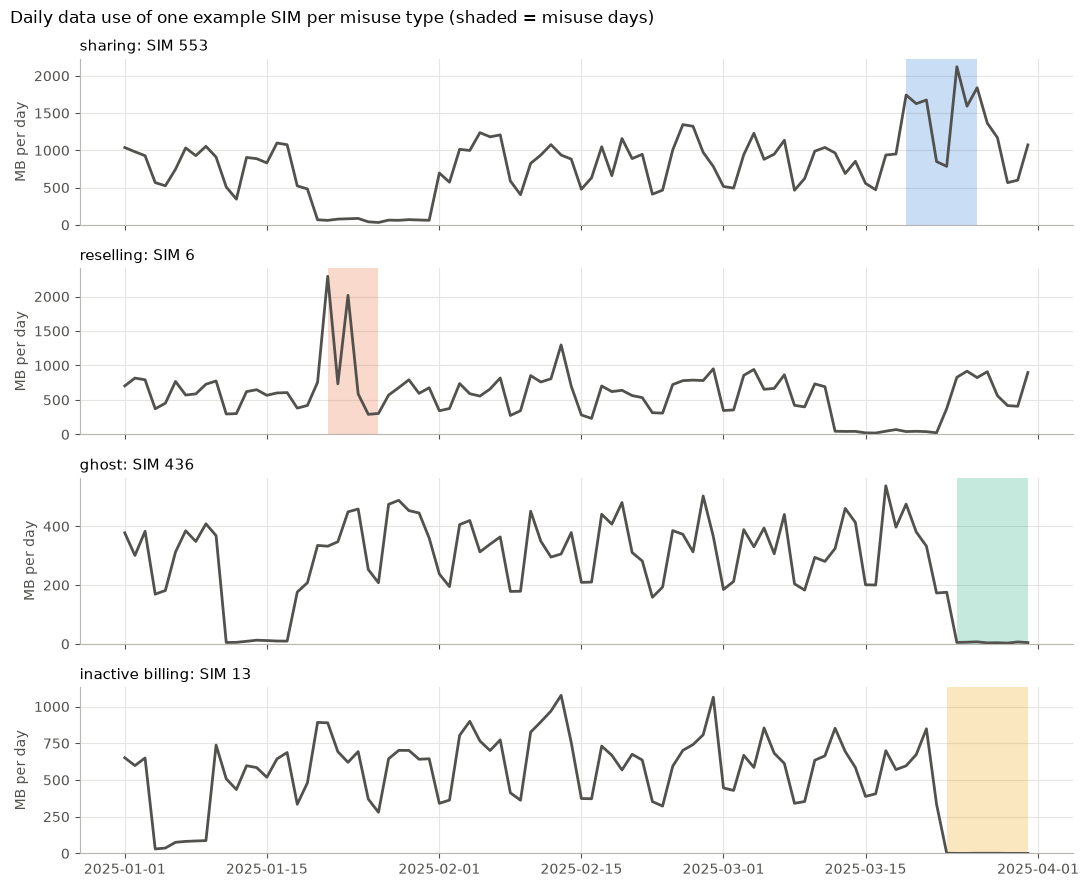

In [10]:
def pick_example(category):
    """A SIM whose episode of this type starts after day 20 (so there is history before it)."""
    cand = episodes[(episodes.category == category) & (episodes.start_day >= 20)].copy()
    cand["gap"] = (cand.duration_days - cand.duration_days.median()).abs()
    return int(cand.sort_values(["gap", "sim_id"]).iloc[0].sim_id)

fig, axes = plt.subplots(len(MISUSE), 1, figsize=(11, 9), sharex=True)
for ax, cat in zip(axes, MISUSE):
    sim = pick_example(cat)
    s = df[df.sim_id == sim].copy()
    s["date"] = pd.to_datetime(s["date"])
    ax.plot(s["date"], s["total_mb"], color="#52514e", linewidth=2)
    in_ep = s["label"] == cat
    ax.fill_between(s["date"], 0, 1, where=in_ep, transform=ax.get_xaxis_transform(),
                    color=CLASS_COLORS[cat], alpha=0.25, step="mid", linewidth=0)
    ax.set_title(f"{SHORT[cat].replace(chr(10), ' ')}: SIM {sim}", loc="left")
    ax.set_ylabel("MB per day")
    ax.set_ylim(bottom=0)
fig.suptitle("Daily data use of one example SIM per misuse type (shaded = misuse days)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
savefig(fig, "eda_example_timeseries.png")
plt.show()

### 2.6 Is inactive billing trivially separable?
If one simple rule finds every inactive-billing day, high model scores on that class reflect how the data was generated, not model skill.

In [11]:
gap = df["billed_mb"] - df["total_mb"]
rule = gap > 1  # billed more than 1 MB above what was actually used
is_ib = df["label"] == "inactive_billing"
print(pd.crosstab(rule.rename("billed > used + 1 MB"), is_ib.rename("label is inactive_billing")))
print()
print("Billed minus used, by class (MB):")
gap.groupby(df["label"]).describe()[["min", "50%", "max"]].reindex(CLASS_ORDER).round(3)

label is inactive_billing  False  True 
billed > used + 1 MB                   
False                      89208      0
True                           0    792

Billed minus used, by class (MB):


,min,50%,max
label,,,
normal,-0.001,0.0,0.001
unauthorized_sharing,-0.001,0.0,0.001
data_reselling,-0.001,0.0,0.001
ghost_usage,-0.001,0.0,0.001
inactive_billing,998.072,2000.0,3000.000


### 2.7 Misuse by subscriber tier

In [12]:
tier_tab = (pd.crosstab(df["tier"], df["label"], normalize="index") * 100).reindex(columns=CLASS_ORDER)
tier_tab.columns = [SHORT[c].replace("\n", " ") for c in tier_tab.columns]
tier_tab.insert(0, "SIM-days", df["tier"].value_counts())
tier_tab.round(2)

,SIM-days,normal,sharing,reselling,ghost,inactive billing
tier,,,,,,
manager,29610,95.20,1.74,0.90,1.29,0.87
professional,46890,94.43,2.25,0.88,1.59,0.86
support,13500,93.59,2.88,0.53,2.00,0.99


### 2.8 Quiet periods vs ghost usage
Some normal periods also have very low data use (e.g. a SIM owner on leave). Which features tell them apart from ghost usage?

In [13]:
low = eda["total_mb"] < 50
print("Days with under 50 MB, by class:")
print(eda.loc[low, "label"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int).to_string())
print(f"Quiet normal days are spread over {eda.loc[low & (eda.label == 'normal'), 'sim_id'].nunique()} SIMs")

QUIET = ["total_mb", "session_count", "unique_towers", "offpeak_share", "voice_minutes_used", "sms_count"]
quiet_vs_ghost = (eda[low & eda.label.isin(["normal", "ghost_usage"])]
                  .groupby("label")[QUIET].median()
                  .rename(index={"normal": "quiet normal days", "ghost_usage": "ghost usage days"}))
quiet_vs_ghost.round(2)

Days with under 50 MB, by class:
label
normal                  1310
unauthorized_sharing      27
data_reselling             4
ghost_usage             1310
inactive_billing         792
Quiet normal days are spread over 199 SIMs


,total_mb,session_count,unique_towers,offpeak_share,voice_minutes_used,sms_count
label,,,,,,
ghost usage days,12.02,6.0,2.0,0.63,0.17,0.0
quiet normal days,10.48,6.0,2.0,0.00,0.00,0.0


### 2.9 Findings

**Data quality.** No missing values or duplicate rows, and every SIM has all 90 days. `voice_minutes_remaining` goes negative on 32 days (lowest −21 minutes), most likely use beyond the bundle; it is left as is.

**Imbalance.** 5.44% of SIM-days are misuse, and 318 of 1,000 SIMs have at least one misuse episode. This calls for class weights in the Random Forest and for precision, recall and PR-AUC rather than accuracy, which would be 94.6% for a model that predicts "normal" every time.

**Episodes are short.** Median length runs from 5 days (data reselling) to 11 days (unauthorized sharing); some last a single day. 35 SIMs have more than one episode.

**Each misuse type has its own signature:**

| Type | What changes compared with normal days |
|---|---|
| Unauthorized sharing | About 2.6× the data (median 1,017 vs 393 MB) and hotspot sessions (median 2 vs 0) |
| Data reselling | More data (median 603 MB), over half of it off-peak (median share 0.56 vs 0). Upload share is the same as normal (0.30 vs 0.29), so upload share alone does not reveal reselling |
| Ghost usage | Almost no data (median 13 MB), fewer sessions (6 vs 10) and towers (2 vs 3), no SMS, and most of that little data off-peak (0.64) |
| Inactive billing | No data, voice or SMS, yet 1,000–3,000 MB billed |

**Inactive billing is perfectly separable.** Billed MB exceeds used MB by more than 1 MB on all 792 inactive-billing days and on no other day; for every other class the gap is within ±0.001 MB. Near-perfect model scores on this class will reflect how the data was generated, which should be stated in the write-up.

**Quiet periods are not misuse.** 1,310 normal days on 199 SIMs have under 50 MB, the same number of days as ghost usage. They match ghost usage on volume, sessions, towers, voice and SMS; only the off-peak share separates them (0.00 vs 0.63). Low usage on its own must therefore not be treated as suspicious.

**Tier matters little.** Misuse affects 4.8% of manager days, 5.6% of professional and 6.4% of support days, mostly through more sharing on support lines. Tier is kept as a feature but is expected to be weak.

**What this means for feature engineering (section 3):**
- Compare each day with the SIM's own recent past, since sharing and reselling are increases on top of very different normal levels.
- Include off-peak share (separates reselling, and separates ghost usage from quiet periods) and hotspot share (sharing).
- Include the billing gap (inactive billing).
- Split train and test by SIM, so episodes on the same SIM never appear on both sides.


## 3. Feature engineering  (issue #3)

- [ ] Raw daily usage features
- [ ] Usage-pattern ratios: upload share, off-peak share, hotspot share, public-APN share, MB per session
- [ ] Billing gap: `billed_mb - total_mb`, billed / used
- [ ] Per-SIM 14-day baseline using PAST days only (`shift(1)` before the rolling window): ratio to median, z-score
- [ ] One-hot encode `tier`; never use `label`, `sim_id` or `date` as features

## 4. Train/test split by SIM  (issue #4)

- [ ] `GroupShuffleSplit(test_size=0.25, random_state=SEED)` with `groups=df['sim_id']`
- [ ] Assert no SIM is in both sets; report the misuse share of each

## 5. Isolation Forest  (issue #5)

- [ ] Fit on training features WITHOUT labels; `contamination` = misuse share (~0.05); `n_jobs=-1`
- [ ] Anomaly score = `-score_samples(X)`; threshold = top `contamination` share of training scores
- [ ] Evaluate with labels: precision, recall, F1, ROC-AUC, PR-AUC, recall per misuse type

## 6. Random Forest  (issue #6)

- [ ] Multiclass, `class_weight='balanced_subsample'`, 300-400 trees, `n_jobs=-1`
- [ ] Optional: tune `max_depth` / `min_samples_leaf` with `GroupKFold` on the training SIMs
- [ ] Classification report per class + confusion matrix (save to `REPORTS_DIR`)

## 7. Compare models  (issue #7)

- [ ] Comparison table: Isolation Forest vs Random Forest
- [ ] Precision-recall curves and feature importance chart (save to `REPORTS_DIR`)
- [ ] Notes for the write-up: inactive-billing separability, data-reselling weakness

## 8. Save models and metadata  (issue #8)

- [ ] Refit both models on ALL SIMs; save with `joblib` to `MODELS_DIR`
- [ ] Save metadata JSON: feature list in order, Isolation Forest threshold, class names, sklearn version
- [ ] Save metrics JSON to `REPORTS_DIR`